# Explainable OSCC classification with EfficientNetB0

This Colab notebook explains an existing trained binary classifier. It does not train, fine-tune, recalibrate, or alter model weights. It computes four explanations for the continuous OSCC sigmoid score: Grad-CAM, Grad-CAM++, LayerCAM, and HiResCAM.

**Clinical scope:** explanations and probabilities are research outputs, not diagnoses. Saliency maps are not lesion segmentation or clinical evidence.


## Fixed model and preprocessing contract

Model path: /content/drive/MyDrive/OSCC V2/best_efficientnetb0.keras. Expected input: (None, 224, 224, 3); output: one sigmoid OSCC score. The nested backbone must be named efficientnetb0 and its final convolutional layer top_conv, producing 7x7x1280 features.

Every uploaded image is decoded to RGB with TensorFlow, resized to 224x224 with antialiasing, and kept in the 0-255 range. Preprocessing is embedded in the saved model. Do not divide by 255 or apply external EfficientNet preprocessing, normalization, CLAHE, or color transforms. The fixed reporting threshold is 0.850266. It is never tuned on these uploaded images; all saliency targets the continuous OSCC score.


In [ ]:
from google.colab import drive, files
from pathlib import Path
import os, json, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

SEED=42
np.random.seed(SEED); tf.random.set_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('Deterministic ops unavailable:',e)
print('TensorFlow',tf.__version__,'devices',tf.config.list_physical_devices())
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError as e: print(e)
drive.mount('/content/drive')
MODEL_PATH='/content/drive/MyDrive/OSCC V2/best_efficientnetb0.keras'
THRESHOLD=0.850266
IMG_SIZE=(224,224)
assert os.path.isfile(MODEL_PATH), f'Model file not found: {MODEL_PATH}'
model=tf.keras.models.load_model(MODEL_PATH,compile=False)
print('Input:',model.input_shape,'output:',model.output_shape)
assert tuple(model.input_shape[1:])==(224,224,3)
assert tuple(model.output_shape[1:])==(1,)
backbone=model.get_layer('efficientnetb0')
last_conv=backbone.get_layer('top_conv')
print('Backbone:',backbone.name,'backbone output:',backbone.output_shape,'top_conv:',last_conv.output.shape)
assert tuple(backbone.output_shape[1:])==(7,7,1280)
assert tuple(last_conv.output.shape[1:])==(7,7,1280)
print('Model layers:',[(i,l.name,type(l).__name__) for i,l in enumerate(model.layers)])



TensorFlow 2.21.0 devices [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Input: (None, 224, 224, 3) output: (None, 1)
Backbone: efficientnetb0 backbone output: (None, 7, 7, 1280) top_conv: (None, 7, 7, 1280)
Model layers: [(0, 'input_layer_1', 'InputLayer'), (1, 'sequential', 'Sequential'), (2, 'efficientnetb0', 'Functional'), (3, 'global_average_pooling2d', 'GlobalAveragePooling2D'), (4, 'batch_normalization', 'BatchNormalization'), (5, 'dropout', 'Dropout'), (6, 'dense', 'Dense'), (7, 'dropout_1', 'Dropout'), (8, 'dense_1', 'Dense')]


## Load test images and preserve the exact input pipeline

Use the upload dialog for one or more image files. No labels or test_metrics.json are needed for explanation. If labels are available, they can be joined later for separate classification evaluation; they do not affect the threshold or maps.


In [ ]:
uploaded=files.upload()
image_paths=[str(Path(name).resolve()) for name in uploaded]
assert image_paths, 'Upload at least one image.'

def load_rgb_0_255(path):
    raw=tf.io.read_file(path)
    image=tf.io.decode_image(raw,channels=3,expand_animations=False)
    image.set_shape([None,None,3])
    image=tf.image.resize(image,IMG_SIZE,antialias=True)
    image=tf.cast(image,tf.float32)
    tf.debugging.assert_all_finite(image,'Non-finite input image values')
    tf.debugging.assert_greater_equal(tf.reduce_min(image),0.)
    tf.debugging.assert_less_equal(tf.reduce_max(image),255.)
    return image
images=tf.stack([load_rgb_0_255(p) for p in image_paths])
print('Image tensor:',images.shape,images.dtype,'range:',float(tf.reduce_min(images)),float(tf.reduce_max(images)))
prob=np.concatenate([model(images[i:i+8],training=False).numpy().reshape(-1) for i in range(0,len(images),8)])
class_names=np.where(prob>=THRESHOLD,'OSCC','Normal')
summary=pd.DataFrame({'image':image_paths,'oscc_probability':prob,'threshold':THRESHOLD,'predicted_class':class_names})
display(summary)



Saving OSCC_400x_67.jpg to OSCC_400x_67.jpg
Image tensor: (1, 224, 224, 3) <dtype: 'float32'> range: 0.15022584795951843 254.14637756347656


,image,oscc_probability,threshold,predicted_class
0,/content/OSCC_400x_67.jpg,0.99983,0.850266,OSCC


## Build an intermediate probe without changing weights

The trained backbone and head layer objects are reused. We replay the model's layers before the nested backbone, expose top_conv, and replay the original head in inference mode. We then verify that the reconstructed probabilities match the complete saved model. This catches graph or layer-order mismatches before producing explanations.


In [ ]:
def inference_call(layer,x):
    try: return layer(x,training=False)
    except TypeError: return layer(x)

backbone_index=model.layers.index(backbone)
# Model prefix reproduces all original input-side layers (including augmentation in inference mode).
def run_prefix(x):
    z=x
    for layer in model.layers[1:backbone_index]: z=inference_call(layer,z)
    return z
conv_probe=tf.keras.Model(backbone.input,[last_conv.output,backbone.output],name='trained_efficientnetb0_conv_probe')
head_layers=model.layers[backbone_index+1:-1]
output_layer=model.layers[-1]
# Exact Grad-CAM++ derivation below requires an inference head that is locally affine
# in the final feature maps before the final sigmoid. Reject unsupported heads explicitly.
allowed=(tf.keras.layers.GlobalAveragePooling2D,tf.keras.layers.GlobalMaxPooling2D,tf.keras.layers.Flatten,tf.keras.layers.BatchNormalization,tf.keras.layers.Dropout,tf.keras.layers.Dense,tf.keras.layers.ReLU,tf.keras.layers.Activation)
unsupported=[(l.name,type(l).__name__) for l in head_layers if not isinstance(l,allowed)]
assert not unsupported, f'Unsupported nonlinear/head layers for exact Grad-CAM++ derivative: {unsupported}'
for layer in head_layers:
    if isinstance(layer,tf.keras.layers.Dense):
        act=tf.keras.activations.serialize(layer.activation)
        assert act in ('linear','relu'), f'Unsupported hidden Dense activation for exact Grad-CAM++: {layer.name} uses {act}'
    if isinstance(layer,tf.keras.layers.Activation):
        act=tf.keras.activations.serialize(layer.activation)
        assert act in ('linear','relu'), f'Unsupported Activation for exact Grad-CAM++: {act}'
assert isinstance(output_layer,tf.keras.layers.Dense), f'Expected sigmoid Dense output; got {type(output_layer).__name__}'
assert output_layer.units==1 and tf.keras.activations.serialize(output_layer.activation)=='sigmoid'

def head_logits_from_backbone_output(backbone_output):
    z=backbone_output
    for layer in head_layers: z=inference_call(layer,z)
    # Read the existing output Dense weights; compute its pre-sigmoid score directly.
    if output_layer.use_bias: logits=tf.linalg.matmul(z,output_layer.kernel)+output_layer.bias
    else: logits=tf.linalg.matmul(z,output_layer.kernel)
    return logits

# Structural check: reconstructed forward path must reproduce the complete saved classifier.
prefix=run_prefix(images)
_,backbone_out=conv_probe(prefix,training=False)
probe_logits=head_logits_from_backbone_output(backbone_out)
probe_prob=tf.math.sigmoid(probe_logits).numpy().reshape(-1)
np.testing.assert_allclose(probe_prob,prob,rtol=2e-4,atol=2e-5)
print('Intermediate probe matches original model. Max absolute score error:',float(np.max(np.abs(probe_prob-prob))))
print('Head layers:',[(l.name,type(l).__name__,getattr(getattr(l,'activation',None),'__name__',None)) for l in head_layers+[output_layer]])



Intermediate probe matches original model. Max absolute score error: 0.0
Head layers: [('global_average_pooling2d', 'GlobalAveragePooling2D', None), ('batch_normalization', 'BatchNormalization', None), ('dropout', 'Dropout', None), ('dense', 'Dense', 'relu'), ('dropout_1', 'Dropout', None), ('dense_1', 'Dense', 'sigmoid')]


## Shared gradients and safe heatmap normalization

All gradient methods differentiate the OSCC sigmoid score, not the thresholded class. The fixed threshold is used only in the prediction table. Maps are resized to the model input and min-max normalized per image for display; a constant map is returned as zeros rather than divided by zero.


In [ ]:
def forward_with_features(x):
    prefix=run_prefix(x)
    A,B=conv_probe(prefix,training=False)
    logits=head_logits_from_backbone_output(B)
    score=tf.math.sigmoid(logits)
    return A,B,logits,score

@tf.function(reduce_retracing=True)
def gradient_bundle(x):
    with tf.GradientTape(persistent=True) as tape:
        A,B,logits,score=forward_with_features(x)
    grad_score=tape.gradient(score,A)
    grad_logit=tape.gradient(logits,A)
    del tape
    return A,score,grad_score,grad_logit

def normalize_map(h):
    h=tf.cast(h,tf.float32)
    h=tf.where(tf.math.is_finite(h),h,tf.zeros_like(h))
    lo=tf.reduce_min(h,axis=[1,2],keepdims=True)
    hi=tf.reduce_max(h,axis=[1,2],keepdims=True)
    return tf.math.divide_no_nan(h-lo,hi-lo)

def resize_maps(h):
    h=tf.image.resize(h[...,None],IMG_SIZE,method='bilinear',antialias=False)[...,0]
    h=normalize_map(h)
    tf.debugging.assert_all_finite(h,'Non-finite saliency map')
    return h

def gradient_maps(x):
    A,score,g,gl=gradient_bundle(x)
    eps=tf.keras.backend.epsilon()
    # Grad-CAM: channel weights are spatial means of d(OSCC score)/dA.
    alpha=tf.reduce_mean(g,axis=[1,2],keepdims=True)
    gradcam=tf.nn.relu(tf.reduce_sum(A*alpha,axis=-1))
    # LayerCAM: positive location-specific gradients weight the feature map before channel summation.
    layercam=tf.nn.relu(tf.reduce_sum(A*tf.nn.relu(g),axis=-1))
    # HiResCAM: preserve spatially specific activation-gradient products.
    hirescam=tf.nn.relu(tf.reduce_sum(A*g,axis=-1))
    # Grad-CAM++ exact derivatives for this piecewise-linear inference head followed by sigmoid.
    # For each activation a, z is locally affine: d2(sigmoid(z))/da2=s''(z)*(dz/da)^2,
    # d3(sigmoid(z))/da3=s'''(z)*(dz/da)^3. This avoids incorrectly treating gradient powers as measured Hessians.
    p=tf.clip_by_value(tf.reshape(score,[-1,1,1,1]),eps,1.-eps)
    s1=p*(1.-p); s2=s1*(1.-2.*p); s3=s1*(1.-6.*p+6.*tf.square(p))
    d1=s1*gl; d2=s2*tf.square(gl); d3=s3*tf.pow(gl,3)
    sum_A=tf.reduce_sum(A,axis=[1,2],keepdims=True)
    denom=2.*d2+sum_A*d3
    alpha_pp=tf.math.divide_no_nan(d2,denom)
    weights=tf.reduce_sum(alpha_pp*tf.nn.relu(d1),axis=[1,2],keepdims=True)
    gradcampp=tf.nn.relu(tf.reduce_sum(weights*A,axis=-1))
    result={'Grad-CAM':gradcam,'Grad-CAM++':gradcampp,'LayerCAM':layercam,'HiResCAM':hirescam}
    return {k:resize_maps(v).numpy() for k,v in result.items()},tf.reshape(score,[-1]).numpy(),A.numpy()




## Grad-CAM++ derivative condition

The Grad-CAM++ equations use second and third derivatives of the target score with respect to each feature-map element. Computing a full Hessian tensor for 7x7x1280 activations is prohibitively large. Here the original classifier head is checked and replayed in inference mode: global pooling, inference BatchNorm, Dense/ReLU layers, then a sigmoid Dense output. The pre-sigmoid logit is locally affine in each feature activation away from ReLU kinks. The notebook therefore computes the per-element second and third score derivatives analytically from the sigmoid derivatives and the exact logit gradient. If the output layer or classifier structure differs from those assumptions, stop and adapt the derivation rather than silently substituting gradient powers.


## Mathematical definitions used

Let A^k be channel k of the trained 7x7 top_conv feature map and let S be the continuous OSCC sigmoid output.

- **Grad-CAM:** alpha_k = mean_ij(dS/dA^k_ij); L = ReLU(sum_k alpha_k A^k).
- **Grad-CAM++:** alpha^k_ij = d2S/d(A^k_ij)^2 / (2 d2S/d(A^k_ij)^2 + sum_ab A^k_ab d3S/d(A^k_ij)^3); w_k = sum_ij alpha^k_ij ReLU(dS/dA^k_ij); L = ReLU(sum_k w_k A^k). The notebook computes these per-element derivatives analytically for the locally affine pre-sigmoid head and sigmoid output.
- **LayerCAM:** L = ReLU(sum_k A^k_ij ReLU(dS/dA^k_ij)).
- **HiResCAM:** L = ReLU(sum_k A^k_ij (dS/dA^k_ij)).

Every heatmap is resized and normalized for visualization only. The model input and score remain unchanged.


In [ ]:
all_maps={k:[] for k in ['Grad-CAM','Grad-CAM++','LayerCAM','HiResCAM']}
for i in range(len(image_paths)):
    x=images[i:i+1]
    gm,score,_=gradient_maps(x)
    for name in all_maps: all_maps[name].append(gm[name][0])
all_maps={k:np.stack(v) for k,v in all_maps.items()}
for name,maps in all_maps.items():
    assert maps.shape==(len(image_paths),224,224), (name,maps.shape)
    assert np.isfinite(maps).all() and maps.min()>=-1e-6 and maps.max()<=1.+1e-6
print('Computed maps:',{k:v.shape for k,v in all_maps.items()})


Computed maps: {'Grad-CAM': (1, 224, 224), 'Grad-CAM++': (1, 224, 224), 'LayerCAM': (1, 224, 224), 'HiResCAM': (1, 224, 224)}


## Visual comparison

Each panel overlays one method's normalized attribution map on the same RGB model input. Maps explain the OSCC score for every image, including images classified Normal. Visualization color and normalization are for display and do not change the model input.


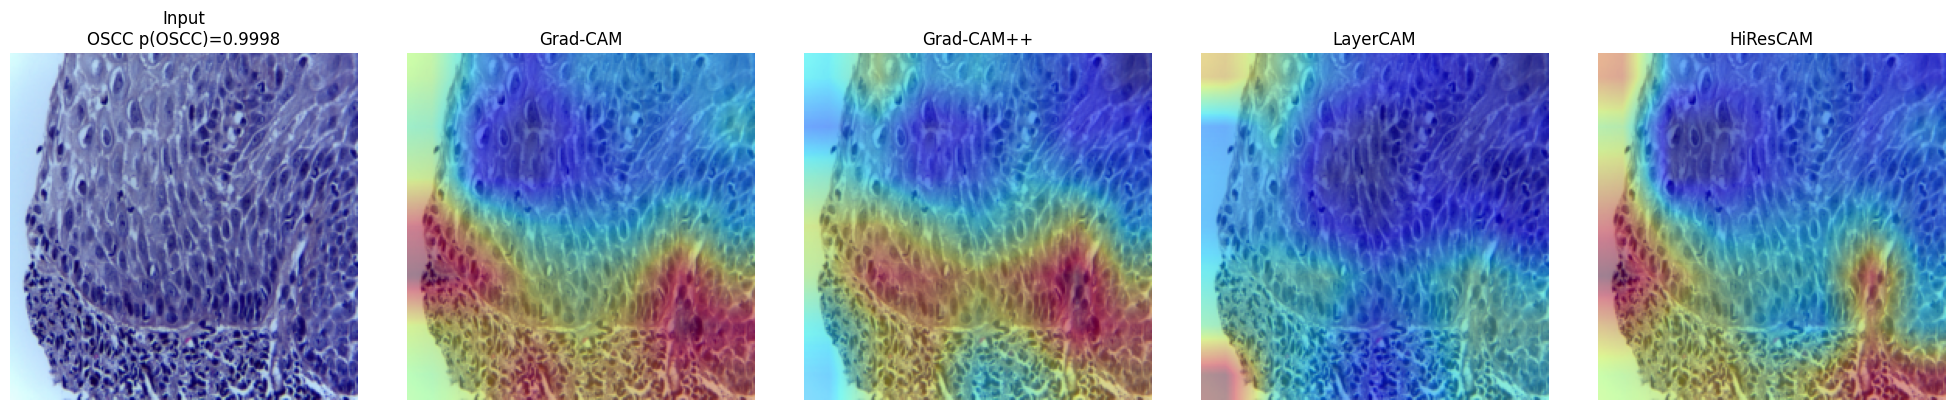

,image,method,oscc_probability,threshold,predicted_class,map_min,map_max
0,/content/OSCC_400x_67.jpg,Grad-CAM,0.99983,0.850266,OSCC,0.0,1.0
1,/content/OSCC_400x_67.jpg,Grad-CAM++,0.99983,0.850266,OSCC,0.0,1.0
2,/content/OSCC_400x_67.jpg,LayerCAM,0.99983,0.850266,OSCC,0.0,1.0
3,/content/OSCC_400x_67.jpg,HiResCAM,0.99983,0.850266,OSCC,0.0,1.0


In [ ]:
OUT_DIR=Path('/content/xai_outputs'); OUT_DIR.mkdir(exist_ok=True)
rows=[]
for i,path in enumerate(image_paths):
    original=images[i].numpy().astype(np.uint8)
    fig,ax=plt.subplots(1,5,figsize=(20,4))
    ax[0].imshow(original); ax[0].set_title(f"Input\n{class_names[i]} p(OSCC)={prob[i]:.4f}")
    for j,name in enumerate(all_maps,1):
        ax[j].imshow(original); ax[j].imshow(all_maps[name][i],cmap='jet',alpha=.42,vmin=0,vmax=1); ax[j].set_title(name)
        np.save(OUT_DIR/f'{Path(path).stem}_{name.lower().replace("+","plus").replace("-","").replace(" ","_")}.npy',all_maps[name][i])
        rows.append(dict(image=path,method=name,oscc_probability=float(prob[i]),threshold=THRESHOLD,predicted_class=class_names[i],map_min=float(all_maps[name][i].min()),map_max=float(all_maps[name][i].max())))
    for a in ax: a.axis('off')
    fig.tight_layout(); fig.savefig(OUT_DIR/f'{Path(path).stem}_comparison.png',dpi=160,bbox_inches='tight'); plt.show()
results=pd.DataFrame(rows); results.to_csv(OUT_DIR/'explanation_summary.csv',index=False)
display(results)


## Perturbation faithfulness evaluation

Deletion progressively replaces the most salient pixels with the image's per-channel mean; insertion starts from that mean image and restores pixels in saliency order. Both curves score the continuous OSCC probability with the original model. Lower deletion AUC and higher insertion AUC indicate stronger faithfulness under this particular perturbation protocol. These interventions can be out of distribution, so interpret them comparatively and alongside the maps. Scores are not thresholded and no test-based threshold selection occurs.


,deletion_auc,insertion_auc,deletion_drop,insertion_gain
method,,,,
HiResCAM,0.791086,0.993540,0.255784,0.255785
Grad-CAM++,0.818467,0.971710,0.255784,0.255785
LayerCAM,0.862821,0.992895,0.255784,0.255785
Grad-CAM,0.880563,0.993357,0.255784,0.255785


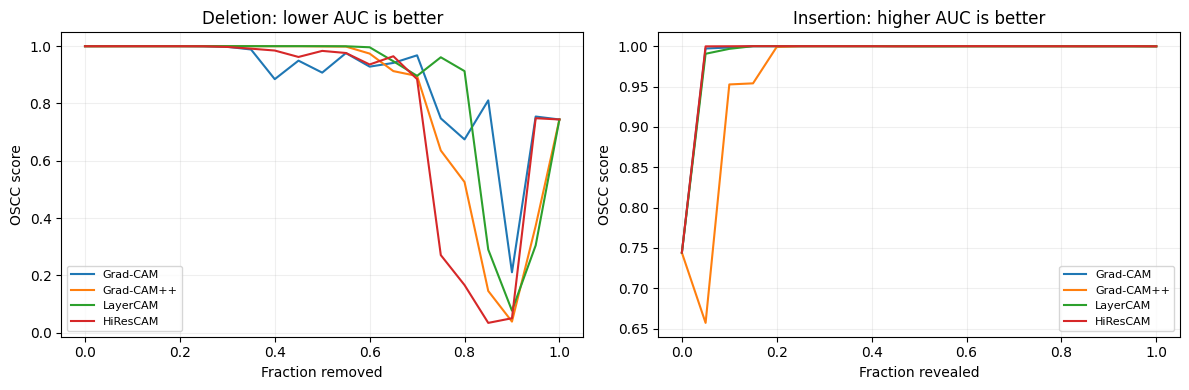

In [ ]:

N_STEPS = 20
PERTURB_BATCH = 8

def perturbation_curve(image, saliency, descending=True):
    flat = np.asarray(saliency).reshape(-1)
    order = np.argsort(flat)[::-1]

    x = image.numpy().astype(np.float32)
    h, w, _ = x.shape

    baseline = np.broadcast_to(
        x.mean(axis=(0, 1), keepdims=True),
        (h, w, 3)
    ).copy()

    fracs = np.linspace(0., 1., N_STEPS + 1)
    variants = []

    for f in fracs:
        n = int(round(f * len(order)))
        mask = np.zeros(len(order), dtype=bool)
        mask[order[:n]] = True
        mask = mask.reshape(h, w, 1)

        if descending:
            v = np.where(mask, baseline, x)
        else:
            v = np.where(mask, x, baseline)

        variants.append(v)

    scores = []

    for st in range(0, len(variants), PERTURB_BATCH):
        batch = tf.convert_to_tensor(
            np.stack(variants[st:st + PERTURB_BATCH]),
            tf.float32
        )

        batch_scores = model(batch, training=False).numpy().reshape(-1)
        scores.extend(batch_scores.tolist())

    return fracs, np.asarray(scores)


faith = []
example_curves = {}

for i in range(len(image_paths)):
    for name, sal in all_maps.items():

        fr, del_scores = perturbation_curve(
            images[i], sal[i], descending=True
        )

        _, ins_scores = perturbation_curve(
            images[i], sal[i], descending=False
        )

        # NumPy-compatible trapezoidal integration
        da = float(np.trapezoid(del_scores, fr))
        ia = float(np.trapezoid(ins_scores, fr))

        faith.append({
            'image': image_paths[i],
            'method': name,
            'deletion_auc': da,
            'insertion_auc': ia,
            'original_score': float(prob[i]),
            'deletion_drop': float(prob[i] - del_scores[-1]),
            'insertion_gain': float(ins_scores[-1] - ins_scores[0])
        })

        if i == 0:
            example_curves[name] = (fr, del_scores, ins_scores)


faith_df = pd.DataFrame(faith)

faith_df.to_csv(
    OUT_DIR / 'faithfulness_metrics.csv',
    index=False
)

display(
    faith_df.groupby('method')[
        ['deletion_auc', 'insertion_auc',
         'deletion_drop', 'insertion_gain']
    ].mean().sort_values('deletion_auc')
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for name, (fr, dv, iv) in example_curves.items():
    ax[0].plot(fr, dv, label=name)
    ax[1].plot(fr, iv, label=name)

ax[0].set(
    title='Deletion: lower AUC is better',
    xlabel='Fraction removed',
    ylabel='OSCC score'
)

ax[1].set(
    title='Insertion: higher AUC is better',
    xlabel='Fraction revealed',
    ylabel='OSCC score'
)

for a in ax:
    a.legend(fontsize=8)
    a.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    OUT_DIR / 'faithfulness_curves.png',
    dpi=160
)
plt.show()


## Reproducibility notes and limitations

The notebook records the TensorFlow version and fixed random seeds, preserves the original saved model, uses deterministic image decoding/resizing, and verifies the intermediate probe against full-model outputs. GPU kernels may still differ slightly across runtimes. Grad-CAM++ uses the exact sigmoid derivatives under the verified piecewise-linear inference-head assumption; its formula is not valid if that head structure check fails. Perturbation metrics depend on the selected mean-color baseline and pixel ranking. Without lesion masks, localization accuracy cannot be measured. Without ground-truth labels, this notebook does not recompute diagnostic classification metrics.

Outputs are saved under /content/xai_outputs and packaged for download.


In [ ]:
import zipfile
zip_path='/content/oscc_xai_results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob('*'):
        if p.is_file(): z.write(p,p.relative_to(OUT_DIR.parent))
print('Saved results:',zip_path)
files.download(zip_path)


Saved results: /content/oscc_xai_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>